# 1x2 MMI Splitter — EME

Simulate a 1x2 MMI splitter with the BEEF library using Eigenmode Expansion (EME).

**Geometry:**
- Single-mode input waveguide -> MMI body -> two output waveguides
- SOI platform: 160 nm Si on SiO2
- Dimensions from typical fabricated device (mm_length = 4.5 um)

**Method:** EME via meow. Fast, no FDTD required. Models the path from the input to each
output waveguide in turn (one solve per output_idx — see the wavelength-sweep cell) and
reports both. For a balanced 1x2 splitter each output carries ~50% of the input power
(ideal insertion loss: -3 dB per port).

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from beef import MMI, EMESolver, SOI_160, plot_eme_geometry

In [2]:
# Global simulation parameters
RESOLUTION = 40.0   # mesh resolution (pixels/um) — used by the EME solver
WL_MIN = 1.26       # wavelength sweep start (um)
WL_MAX = 1.36       # wavelength sweep end (um)
N_WL = 11           # number of wavelength points

In [ ]:
# Persistent on-disk simulation cache (see beef/cache/) — a solve_section()
# call whose config matches a prior cached run loads that result instead of
# re-simulating. Assumes this notebook runs from its own directory
# (examples/mmi_1x2/), matching mmi_1x2_eme.py's save_dir.
save_dir = os.path.abspath(os.path.join("..", "..", "..", "..", "example_sim_cache"))

# Notebook-only: never actually run a simulation here, only render from an
# already-populated cache — the script populates save_dir first; this
# notebook is for docs/rendering and must not silently kick off a fresh
# (possibly multi-hour) run. Raises CacheMissError if something isn't cached.
CACHE_ONLY = True

In [4]:
# 1. Define geometry
mmi = MMI(
    n_inputs=1,             # 1x2 splitter
    n_outputs=2,
    mm_length=4.5,          # MMI body length (um)
    mm_width=2.0,           # MMI body width (um)
    waveguide_width=0.35,   # single-mode access waveguide width (um)
    taper_length=1.0,       # input/output taper length (um)
    taper_width=0.8,        # taper width at MMI junction (um)
    waveguide_offset=1.0,   # center-to-center output spacing (um)
    waveguide_height=0.16,  # Si layer thickness (um) — SOI_160
)

print(f"MMI total length: {mmi.total_length:.2f} um")

MMI total length: 6.50 um


In [5]:
# 2. Configure EME solver
solver = EMESolver(
    # 5 regions: wg_in | taper_in | MMI body | taper_out | wg_out
    num_modes=[1,   5,   12,  5,   1  ],  # modes per region
    num_cells=[1,   8,  1,   8,  1  ],  # cells per region (tapers subdivided)
    lengths=  [0.5, 1.0, 4.5, 1.0, 0.5], # region lengths (um)
    oxide_width=5.0,                       # cross-section mesh y-span (um)
    oxide_height=1.5,                      # cross-section mesh z-span (um)
    res=RESOLUTION,                        # mesh pts/um
    material_stack=SOI_160,                # 160 nm SOI stack
    mode_solver="tidy3d",                  # tidy3d-backed mode solver (no FDTD section to stay consistent with)
)

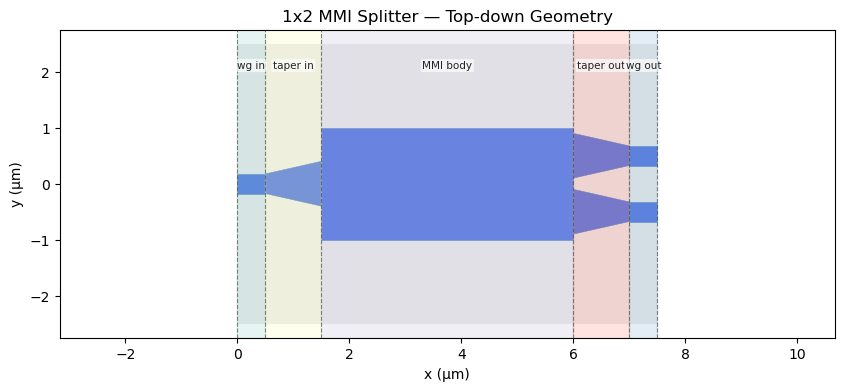

In [6]:
# 3. Geometry plot
plot_eme_geometry(
    mmi, solver=solver,
    region_labels=["wg in", "taper in", "MMI body", "taper out", "wg out"],
    title="1x2 MMI Splitter — Top-down Geometry",
    # output_idx omitted (defaults to None) — draws both output branches,
    # since both are solved below (each solve() call restricts them one at
    # a time; the plot shows the full device for reference).
)
plt.show()

In [ ]:
# 4. Wavelength sweep
wavelengths = np.linspace(WL_MIN, WL_MAX, N_WL)  # um, O-band

print(f"Sweeping {len(wavelengths)} wavelengths: "
      f"{wavelengths[0]:.3f} - {wavelengths[-1]:.3f} um")

# solve()'s single **kwargs call applies the same output_idx to every entry
# in `ports`, so measuring both outputs accurately takes two separate calls
# — one per output_idx — each restricting the EME cross-sections to that
# one output branch only (output_ys[idx]), giving the isolated waveguide
# mode rather than a supermode of both outputs (the two branches are
# waveguide_offset - waveguide_width = 0.65 um apart edge-to-edge past the
# taper, comfortably decoupled). Results are merged into one SMatrix.
smat_top = solver.solve(mmi, wavelengths, ports=["out_top"], output_idx=1, save_dir=save_dir, cache_only=CACHE_ONLY)
smat_bot = solver.solve(mmi, wavelengths, ports=["out_bot"], output_idx=0, save_dir=save_dir, cache_only=CACHE_ONLY)
smat = smat_top
smat._data.update(smat_bot._data)
smat.check_passive()  # sanity: total output power must not exceed 1 at any wavelength

In [8]:
# 5. Print summary
T_top, T_bot = smat.transmission("out_top"), smat.transmission("out_bot")
T_total = T_top + T_bot
wl_center = wavelengths[len(wavelengths) // 2]
idx = np.argmin(np.abs(wavelengths - wl_center))

print(f"\nResults at wavelength = {wl_center:.3f} um:")
print(f"  Top output    T = {T_top[idx]:.4f}  IL = {10*np.log10(max(T_top[idx],1e-20)):.2f} dB")
print(f"  Bottom output T = {T_bot[idx]:.4f}  IL = {10*np.log10(max(T_bot[idx],1e-20)):.2f} dB")
print(f"  Total         T = {T_total[idx]:.4f}  IL = {10*np.log10(max(T_total[idx],1e-20)):.2f} dB")
print(f"  (ideal 50/50 split -> T_each=0.5, IL_total=0.0 dB)")


Results at wavelength = 1.310 um:
  Top output    T = 0.4278  IL = -3.69 dB
  Bottom output T = 0.4278  IL = -3.69 dB
  Total         T = 0.8556  IL = -0.68 dB
  (ideal 50/50 split -> T_each=0.5, IL_total=0.0 dB)


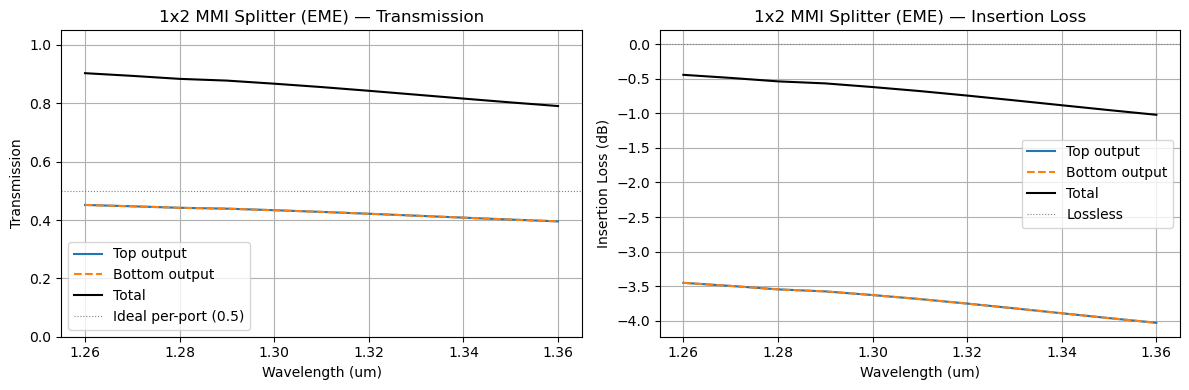

In [9]:
# 6. Performance plot — transmission and insertion loss vs wavelength
fig, (ax_lin, ax_db) = plt.subplots(1, 2, figsize=(12, 4))

ax_lin.plot(wavelengths, T_top, label="Top output")
ax_lin.plot(wavelengths, T_bot, label="Bottom output", linestyle="--")
ax_lin.plot(wavelengths, T_total, label="Total", color="k", lw=1.5)
ax_lin.axhline(0.5, color="gray", linestyle=":", lw=0.8, label="Ideal per-port (0.5)")
ax_lin.set_xlabel("Wavelength (um)")
ax_lin.set_ylabel("Transmission")
ax_lin.set_title("1x2 MMI Splitter (EME) — Transmission")
ax_lin.legend()
ax_lin.grid(True)
ax_lin.set_ylim(0, 1.05)

IL_top = 10 * np.log10(np.clip(T_top, 1e-20, None))
IL_bot = 10 * np.log10(np.clip(T_bot, 1e-20, None))
IL_tot = 10 * np.log10(np.clip(T_total, 1e-20, None))
ax_db.plot(wavelengths, IL_top, label="Top output")
ax_db.plot(wavelengths, IL_bot, label="Bottom output", linestyle="--")
ax_db.plot(wavelengths, IL_tot, label="Total", color="k", lw=1.5)
ax_db.axhline(0.0, color="gray", linestyle=":", lw=0.8, label="Lossless")
ax_db.set_xlabel("Wavelength (um)")
ax_db.set_ylabel("Insertion Loss (dB)")
ax_db.set_title("1x2 MMI Splitter (EME) — Insertion Loss")
ax_db.legend()
ax_db.grid(True)

plt.tight_layout()
plt.show()